# 🧪 Medical Image Preprocessing — Memory-Efficient Pipeline
## X-Ray · CT Scan · MRI Brain Tumor (Kaggle)

**Root cause of MemoryError (fixed here):**
The previous version loaded ALL images into a Python list, then called `np.array(list)` which
needed ~12 GB RAM for 21k X-Ray images. This version writes **directly to disk using `np.memmap`**,
processing one image at a time. RAM usage stays under ~500 MB regardless of dataset size.

**Dataset folder expected at `DATASETS/` next to this notebook:**
**Output:** `preprocessed/{xray,ct,mri}/{train,val,test}/{X.npy, y.npy}` + `classes.npy`

In [1]:
# ── CELL 1 — Imports & Config ────────────────────────────────────────────────
import os, gc, warnings
import numpy as np
import cv2
from pathlib import Path
from collections import Counter
from PIL import Image as PILImage
warnings.filterwarnings('ignore')

SEED      = 42
IMG_SIZE  = 224
VAL_RATIO = 0.15   # fraction of training set used for validation
TEST_RATIO = 0.15  # fraction of full set used for test (only when no pre-made test split)

np.random.seed(SEED)

# ── DATASET ROOT — adjust if your folder is named differently ────────────────
DATA_DIR = Path('DATASETS')   # folder next to this notebook
OUT_DIR  = Path('preprocessed')
OUT_DIR.mkdir(exist_ok=True)

print(f'Data root : {DATA_DIR.resolve()}')
print(f'Output    : {OUT_DIR.resolve()}')
print(f'IMG_SIZE  : {IMG_SIZE}')
print()
if not DATA_DIR.exists():
    print(f'⚠️  WARNING: {DATA_DIR.resolve()} does not exist!')
    print('    Create it or change DATA_DIR above.')
else:
    print('✅ Data root found. Contents:')
    for p in sorted(DATA_DIR.iterdir()):
        print(f'   {p.name}/')

Data root : F:\SRUJANA FINAL\DATASETS
Output    : F:\SRUJANA FINAL\preprocessed
IMG_SIZE  : 224

✅ Data root found. Contents:
   CT/
   MRI/
   XRAY/


In [ ]:
VALID_EXTS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}

def list_image_paths(folder: Path):
    """Return sorted list of image paths in folder (non-recursive)."""
    return sorted([p for p in folder.iterdir()
                   if p.suffix.lower() in VALID_EXTS])


def read_image(path: Path) -> np.ndarray:
    """Read one image → uint8 RGB (IMG_SIZE, IMG_SIZE, 3). Returns None on error."""
    try:
        img = PILImage.open(path).convert('RGB')
        img = img.resize((IMG_SIZE, IMG_SIZE), PILImage.LANCZOS)
        return np.array(img, dtype=np.uint8)
    except Exception as e:
        print(f'  ⚠️  Skip {path.name}: {e}')
        return None


# ── Per-modality preprocessing functions ─────────────────────────────────────

def preprocess_xray(img_uint8: np.ndarray) -> np.ndarray:
    """Grayscale → CLAHE → 3-channel float32 [0,1]."""
    gray  = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    gray  = clahe.apply(gray)
    f     = gray.astype(np.float32) / 255.0
    return np.stack([f, f, f], axis=-1)


def preprocess_ct(img_uint8: np.ndarray) -> np.ndarray:
    """RGB → mild Gaussian denoising → float32 [0,1]."""
    img = cv2.GaussianBlur(img_uint8, (3, 3), 0)
    return img.astype(np.float32) / 255.0


def preprocess_mri(img_uint8: np.ndarray) -> np.ndarray:
    """Grayscale → percentile normalisation [2,98] → 3-channel float32 [0,1]."""
    gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY).astype(np.float32)
    p2, p98 = np.percentile(gray, [2, 98])
    gray    = np.clip(gray, p2, p98)
    gray    = (gray - p2) / (p98 - p2 + 1e-8)
    return np.stack([gray, gray, gray], axis=-1).astype(np.float32)


# ── Low-RAM save helper ───────────────────────────────────────────────────────

def write_split_memmap(paths_labels, preprocess_fn, out_dir: Path, split: str,
                       chunk_size: int = 64):
    """
    Write a split to disk using np.memmap, processing `chunk_size` images at a time.
    RAM usage = chunk_size × 224 × 224 × 3 × 4 bytes ≈ 9.6 MB per chunk of 64.
    """
    out_dir.mkdir(parents=True, exist_ok=True)
    n = len(paths_labels)
    if n == 0:
        print(f'    ⚠️  {split}: 0 samples — skipping')
        return 0

    x_path = str(out_dir / 'X.npy')
    y_path = str(out_dir / 'y.npy')

    # Pre-allocate memmap on disk — only reserves disk space, not RAM
    X_mm = np.memmap(x_path, dtype='float32', mode='w+',
                     shape=(n, IMG_SIZE, IMG_SIZE, 3))
    y_arr = np.zeros(n, dtype=np.int64)

    written = 0
    for start in range(0, n, chunk_size):
        chunk = paths_labels[start:start + chunk_size]
        for local_i, (path, label) in enumerate(chunk):
            raw = read_image(path)
            if raw is None:
                # Use a blank image so indices stay consistent
                X_mm[written + local_i] = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
            else:
                X_mm[written + local_i] = preprocess_fn(raw)
            y_arr[written + local_i] = label
        X_mm.flush()  # flush each chunk to disk
        written += len(chunk)

    del X_mm  # close memmap — data stays on disk
    np.save(y_path, y_arr)
    print(f'    ✅ {split:5s}: {n:6d} samples  dist={dict(sorted(Counter(y_arr.tolist()).items()))}')
    gc.collect()
    return n


def stratified_split_indices(labels: np.ndarray, val_ratio: float, test_ratio: float,
                              seed: int = 42):
    """
    Returns (train_idx, val_idx, test_idx) — integer arrays only, no image data.
    Stratified: each class is split proportionally.
    Works even for very small classes (falls back gracefully).
    """
    rng   = np.random.default_rng(seed)
    n     = len(labels)
    tr_i, va_i, te_i = [], [], []

    for cls in np.unique(labels):
        idx = np.where(labels == cls)[0]
        rng.shuffle(idx)
        n_cls = len(idx)

        # Minimum 1 sample per split if class is very small
        n_test = max(1, int(n_cls * test_ratio))
        n_val  = max(1, int(n_cls * val_ratio))
        # Make sure train always gets at least 1
        n_val  = min(n_val,  n_cls - n_test - 1)
        n_test = min(n_test, n_cls - 1)
        n_val  = max(1, n_val)

        te_i.extend(idx[:n_test].tolist())
        va_i.extend(idx[n_test:n_test + n_val].tolist())
        tr_i.extend(idx[n_test + n_val:].tolist())

    return (np.array(tr_i, dtype=np.int64),
            np.array(va_i, dtype=np.int64),
            np.array(te_i, dtype=np.int64))


def copy_split_from_memmap(src_x_path: str, all_paths_labels: list,
                            indices: np.ndarray, preprocess_fn,
                            out_dir: Path, split: str, chunk_size: int = 64):
    """
    Used when we need to subset a memmap by indices (e.g. for train/val/test split).
    Reads from disk → applies preprocessing → writes to new memmap.
    RAM peak = chunk_size images at a time.
    """
    n     = len(indices)
    out_dir.mkdir(parents=True, exist_ok=True)
    if n == 0:
        print(f'    ⚠️  {split}: 0 samples — skipping')
        return 0

    x_out  = str(out_dir / 'X.npy')
    y_out  = str(out_dir / 'y.npy')

    X_mm  = np.memmap(x_out, dtype='float32', mode='w+',
                      shape=(n, IMG_SIZE, IMG_SIZE, 3))
    y_arr = np.zeros(n, dtype=np.int64)

    for out_i, src_i in enumerate(indices):
        path, label = all_paths_labels[src_i]
        raw = read_image(path)
        X_mm[out_i] = preprocess_fn(raw) if raw is not None else np.zeros(
            (IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
        y_arr[out_i] = label
        if (out_i + 1) % chunk_size == 0:
            X_mm.flush()

    X_mm.flush()
    del X_mm
    np.save(y_out, y_arr)
    print(f'    ✅ {split:5s}: {n:6d} samples  dist={dict(sorted(Counter(y_arr.tolist()).items()))}')
    gc.collect()
    return n


print('✅ Memory-efficient preprocessing functions ready.')
print(f'   Peak RAM per chunk: {64 * 224 * 224 * 3 * 4 / 1024**2:.1f} MB  (chunk_size=64)')

✅ Memory-efficient preprocessing functions ready.
   Peak RAM per chunk: 36.8 MB  (chunk_size=64)


In [ ]:
print('\n' + '='*65)
print('X-RAY PREPROCESSING')
print('='*65)

XRAY_CLASSES = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

# ── Locate the XRAY folder (case-safe) ───────────────────────────────────────
xray_base = None
for candidate in ['XRAY', 'xray', 'Xray', 'X-Ray', 'x-ray']:
    p = DATA_DIR / candidate
    if p.exists():
        xray_base = p
        break

if xray_base is None:
    raise FileNotFoundError(
        f'XRAY folder not found inside {DATA_DIR.resolve()}\n'
        f'Tried: XRAY, xray, Xray, X-Ray, x-ray'
    )
print(f'Found XRAY at: {xray_base.resolve()}')

# ── Check if already split ────────────────────────────────────────────────────
xray_has_splits = all((xray_base / s).exists() for s in ['train', 'val', 'test'])

xray_out = OUT_DIR / 'xray'
xray_out.mkdir(exist_ok=True)

# =====================================================================
# CASE A — Pre-split train/val/test folders already exist
# =====================================================================
if xray_has_splits:
    print('Mode: Pre-split train/val/test folders found.')

    for split in ['train', 'val', 'test']:
        paths_labels = []
        for lid, cls in enumerate(XRAY_CLASSES):
            cls_dir = xray_base / split / cls
            if not cls_dir.exists():
                print(f'  ⚠️  Missing: {cls_dir}')
                continue
            paths = list_image_paths(cls_dir)
            for p in paths:
                paths_labels.append((p, lid))
            print(f'  [{split}] {cls}: {len(paths)} images')

        # Shuffle before writing
        rng = np.random.default_rng(SEED)
        rng.shuffle(paths_labels)
        write_split_memmap(paths_labels, preprocess_xray, xray_out / split, split)

# =====================================================================
# CASE B — Class folders → stratified split (MEMORY-SAFE)
# =====================================================================
else:
    print('Mode: Class folders → stratified train/val/test split.')

    all_paths_labels = []
    for lid, cls in enumerate(XRAY_CLASSES):
        # Support both XRAY/COVID/ and XRAY/COVID/images/
        cls_dir = xray_base / cls / 'images'
        if not cls_dir.exists():
            cls_dir = xray_base / cls
        if not cls_dir.exists():
            print(f'  ⚠️  Not found: {cls}')
            continue
        paths = list_image_paths(cls_dir)
        print(f'  {cls}: {len(paths)} images')
        for p in paths:
            all_paths_labels.append((p, lid))

    if len(all_paths_labels) == 0:
        raise FileNotFoundError('No X-Ray images found. Check DATASETS/XRAY folder.')

    # Split on indices — NO image data in RAM during split
    all_labels_arr = np.array([lb for _, lb in all_paths_labels], dtype=np.int64)
    tr_idx, va_idx, te_idx = stratified_split_indices(
        all_labels_arr, VAL_RATIO, TEST_RATIO, SEED)

    print(f'  Split: train={len(tr_idx)}, val={len(va_idx)}, test={len(te_idx)}')

    # Write each split directly to disk, image by image
    for split, indices in [('train', tr_idx), ('val', va_idx), ('test', te_idx)]:
        subset = [all_paths_labels[i] for i in indices]
        write_split_memmap(subset, preprocess_xray, xray_out / split, split)

np.save(str(xray_out / 'classes.npy'), np.array(XRAY_CLASSES))
print(f'\n✅ X-Ray complete. Classes: {XRAY_CLASSES}')
gc.collect()


X-RAY PREPROCESSING
Found XRAY at: F:\SRUJANA FINAL\DATASETS\XRAY
Mode: Class folders → stratified train/val/test split.
  COVID: 3616 images
  Lung_Opacity: 6012 images
  Normal: 10192 images
  Viral Pneumonia: 1345 images
  Split: train=14821, val=3172, test=3172
    ✅ train:  14821 samples  dist={0: 2532, 1: 4210, 2: 7136, 3: 943}
    ✅ val  :   3172 samples  dist={0: 542, 1: 901, 2: 1528, 3: 201}
    ✅ test :   3172 samples  dist={0: 542, 1: 901, 2: 1528, 3: 201}

✅ X-Ray complete. Classes: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']


0

In [ ]:
print('\n' + '='*65)
print('CT SCAN PREPROCESSING')
print('='*65)

CT_CLASSES      = ['adenocarcinoma', 'large cell carcinoma',
                   'normal', 'squamous cell carcinoma']
# Folder names use dots (dataset convention)
CT_FOLDER_NAMES = ['adenocarcinoma', 'large.cell.carcinoma',
                   'normal', 'squamous.cell.carcinoma']

# ── Locate CT folder ─────────────────────────────────────────────────────────
ct_base = None
for candidate in ['CT', 'ct', 'Ct', 'CT_Scan', 'ct_scan']:
    p = DATA_DIR / candidate
    if p.exists():
        ct_base = p
        break

if ct_base is None:
    raise FileNotFoundError(
        f'CT folder not found inside {DATA_DIR.resolve()}\n'
        f'Tried: CT, ct, Ct, CT_Scan, ct_scan'
    )
print(f'Found CT at: {ct_base.resolve()}')

ct_out = OUT_DIR / 'ct'
ct_out.mkdir(exist_ok=True)

ct_has_splits = (ct_base / 'train').exists() and (ct_base / 'test').exists()

# =====================================================================
# CASE A — Pre-split train/test folders (LEAKAGE-SAFE)
# =====================================================================
if ct_has_splits:
    print('Mode: Pre-split train/test folders found (leakage-safe).')

    # ── Training data → split into train + val ────────────────────────
    train_paths_labels = []
    for lid, (cls, folder) in enumerate(zip(CT_CLASSES, CT_FOLDER_NAMES)):
        tr_dir = ct_base / 'train' / folder
        if not tr_dir.exists():
            tr_dir = ct_base / 'train' / cls
        if not tr_dir.exists():
            print(f'  ⚠️  Not found: {tr_dir}')
            continue
        paths = list_image_paths(tr_dir)
        print(f'  [train_src] {cls}: {len(paths)} images')
        for p in paths:
            train_paths_labels.append((p, lid))

    # Split train→ train/val on indices only
    tr_labels_arr = np.array([lb for _, lb in train_paths_labels], dtype=np.int64)
    tr_idx, va_idx, _ = stratified_split_indices(
        tr_labels_arr, val_ratio=VAL_RATIO, test_ratio=0.0, seed=SEED)

    tr_subset = [train_paths_labels[i] for i in tr_idx]
    va_subset = [train_paths_labels[i] for i in va_idx]

    write_split_memmap(tr_subset, preprocess_ct, ct_out / 'train', 'train')
    write_split_memmap(va_subset, preprocess_ct, ct_out / 'val',   'val')

    # ── Test data — ONLY from dataset test folder ─────────────────────
    test_paths_labels = []
    for lid, (cls, folder) in enumerate(zip(CT_CLASSES, CT_FOLDER_NAMES)):
        te_dir = ct_base / 'test' / folder
        if not te_dir.exists():
            te_dir = ct_base / 'test' / cls
        if not te_dir.exists():
            print(f'  ⚠️  Test not found: {cls}')
            continue
        paths = list_image_paths(te_dir)
        print(f'  [test_src]  {cls}: {len(paths)} images')
        for p in paths:
            test_paths_labels.append((p, lid))

    write_split_memmap(test_paths_labels, preprocess_ct, ct_out / 'test', 'test')

# =====================================================================
# CASE B — Class folders only → stratified split
# =====================================================================
else:
    print('Mode: Class folders → stratified split.')

    all_paths_labels = []
    for lid, (cls, folder) in enumerate(zip(CT_CLASSES, CT_FOLDER_NAMES)):
        cls_dir = ct_base / folder
        if not cls_dir.exists():
            cls_dir = ct_base / cls
        if not cls_dir.exists():
            print(f'  ⚠️  Not found: {cls}')
            continue
        paths = list_image_paths(cls_dir)
        print(f'  {cls}: {len(paths)} images')
        for p in paths:
            all_paths_labels.append((p, lid))

    all_labels_arr = np.array([lb for _, lb in all_paths_labels], dtype=np.int64)
    tr_idx, va_idx, te_idx = stratified_split_indices(
        all_labels_arr, VAL_RATIO, TEST_RATIO, SEED)

    for split, indices in [('train', tr_idx), ('val', va_idx), ('test', te_idx)]:
        subset = [all_paths_labels[i] for i in indices]
        write_split_memmap(subset, preprocess_ct, ct_out / split, split)

np.save(str(ct_out / 'classes.npy'), np.array(CT_CLASSES))
print(f'\n✅ CT complete. Classes: {CT_CLASSES}')
gc.collect()


CT SCAN PREPROCESSING
Found CT at: F:\SRUJANA FINAL\DATASETS\CT
Mode: Pre-split train/test folders found (leakage-safe).
  [train_src] adenocarcinoma: 195 images
  [train_src] large cell carcinoma: 115 images
  [train_src] normal: 148 images
  [train_src] squamous cell carcinoma: 155 images
    ✅ train:    518 samples  dist={0: 165, 1: 97, 2: 125, 3: 131}
    ✅ val  :     91 samples  dist={0: 29, 1: 17, 2: 22, 3: 23}
  [test_src]  adenocarcinoma: 120 images
  [test_src]  large cell carcinoma: 51 images
  [test_src]  normal: 54 images
  [test_src]  squamous cell carcinoma: 90 images
    ✅ test :    315 samples  dist={0: 120, 1: 51, 2: 54, 3: 90}

✅ CT complete. Classes: ['adenocarcinoma', 'large cell carcinoma', 'normal', 'squamous cell carcinoma']


0

In [ ]:
print('\n' + '='*65)
print('MRI BRAIN TUMOR PREPROCESSING')
print('(Kaggle Brain Tumor MRI — glioma/meningioma/notumor/pituitary)')
print('='*65)

MRI_CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']

# ── Locate MRI folder ─────────────────────────────────────────────────────────
mri_base = None
for candidate in ['MRI', 'mri', 'Mri', 'Brain_Tumor', 'brain_tumor']:
    p = DATA_DIR / candidate
    if p.exists():
        mri_base = p
        break

if mri_base is None:
    raise FileNotFoundError(
        f'MRI folder not found inside {DATA_DIR.resolve()}\n'
        f'Tried: MRI, mri, Mri, Brain_Tumor\n'
        f'Download: kaggle datasets download masoudnickparvar/brain-tumor-mri-dataset'
    )
print(f'Found MRI at: {mri_base.resolve()}')

# Kaggle dataset uses Training/Testing (capital T)
mri_train_root = None
mri_test_root  = None
for t_name in ['Training', 'training', 'train']:
    p = mri_base / t_name
    if p.exists(): mri_train_root = p; break
for t_name in ['Testing', 'testing', 'test']:
    p = mri_base / t_name
    if p.exists(): mri_test_root = p; break

if mri_train_root is None:
    raise FileNotFoundError(
        f'MRI Training subfolder not found inside {mri_base.resolve()}\n'
        f'Expected: Training/ or training/'
    )
print(f'  Training root: {mri_train_root}')
print(f'  Testing root : {mri_test_root}')

mri_out = OUT_DIR / 'mri'
mri_out.mkdir(exist_ok=True)

# ── Training data → train + val split ────────────────────────────────────────
train_paths_labels = []
for lid, cls in enumerate(MRI_CLASSES):
    cls_dir = mri_train_root / cls
    if not cls_dir.exists():
        print(f'  ⚠️  Not found: {cls_dir}')
        continue
    paths = list_image_paths(cls_dir)
    print(f'  [Training] {cls}: {len(paths)} images')
    for p in paths:
        train_paths_labels.append((p, lid))

if len(train_paths_labels) == 0:
    raise FileNotFoundError('No MRI training images found.')

# Split train → train/val on indices only
tr_labels_arr = np.array([lb for _, lb in train_paths_labels], dtype=np.int64)
tr_idx, va_idx, _ = stratified_split_indices(
    tr_labels_arr, val_ratio=VAL_RATIO, test_ratio=0.0, seed=SEED)

tr_subset = [train_paths_labels[i] for i in tr_idx]
va_subset = [train_paths_labels[i] for i in va_idx]

write_split_memmap(tr_subset, preprocess_mri, mri_out / 'train', 'train')
write_split_memmap(va_subset, preprocess_mri, mri_out / 'val',   'val')

# ── Testing data → test split only ───────────────────────────────────────────
if mri_test_root is not None:
    test_paths_labels = []
    for lid, cls in enumerate(MRI_CLASSES):
        cls_dir = mri_test_root / cls
        if not cls_dir.exists():
            print(f'  ⚠️  Not found: {cls_dir}')
            continue
        paths = list_image_paths(cls_dir)
        print(f'  [Testing]  {cls}: {len(paths)} images')
        for p in paths:
            test_paths_labels.append((p, lid))
    write_split_memmap(test_paths_labels, preprocess_mri, mri_out / 'test', 'test')
else:
    # No test folder — carve out from training
    print('  ⚠️  No Testing folder found — carving test from training.')
    te_labels_arr = np.array([lb for _, lb in train_paths_labels], dtype=np.int64)
    tr2_idx, va2_idx, te2_idx = stratified_split_indices(
        te_labels_arr, VAL_RATIO, TEST_RATIO, SEED)
    te_subset = [train_paths_labels[i] for i in te2_idx]
    write_split_memmap(te_subset, preprocess_mri, mri_out / 'test', 'test')

np.save(str(mri_out / 'classes.npy'), np.array(MRI_CLASSES))
print(f'\n✅ MRI complete. Classes: {MRI_CLASSES}')
gc.collect()


MRI BRAIN TUMOR PREPROCESSING
(Kaggle Brain Tumor MRI — glioma/meningioma/notumor/pituitary)
Found MRI at: F:\SRUJANA FINAL\DATASETS\MRI
  Training root: DATASETS\MRI\Training
  Testing root : DATASETS\MRI\Testing
  [Training] glioma: 1400 images
  [Training] meningioma: 1400 images
  [Training] notumor: 1400 images
  [Training] pituitary: 1400 images
    ✅ train:   4756 samples  dist={0: 1189, 1: 1189, 2: 1189, 3: 1189}
    ✅ val  :    840 samples  dist={0: 210, 1: 210, 2: 210, 3: 210}
  [Testing]  glioma: 400 images
  [Testing]  meningioma: 400 images
  [Testing]  notumor: 400 images
  [Testing]  pituitary: 400 images
    ✅ test :   1600 samples  dist={0: 400, 1: 400, 2: 400, 3: 400}

✅ MRI complete. Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


0

In [6]:
# ── CELL 6 — Final Verification ──────────────────────────────────────────────
# Reads only y.npy (integers, tiny) + a few rows of X.npy to spot-check.
# Does NOT load the full X into RAM.

print('\n' + '='*65)
print('FINAL VERIFICATION')
print('='*65)

all_passed = True

for mod in ['xray', 'ct', 'mri']:
    for split in ['train', 'val', 'test']:
        x_path = OUT_DIR / mod / split / 'X.npy'
        y_path = OUT_DIR / mod / split / 'y.npy'

        if not (x_path.exists() and y_path.exists()):
            print(f'  ❌ MISSING: {mod}/{split}')
            all_passed = False
            continue

        # Load labels (tiny — safe)
        y = np.load(str(y_path))
        n = len(y)

        # Check memmap shape consistency
        mm = np.memmap(str(x_path), dtype='float32', mode='r')
        expected = n * IMG_SIZE * IMG_SIZE * 3
        if mm.size != expected:
            print(f'  ❌ SHAPE MISMATCH: {mod}/{split}  '
                  f'X has {mm.size} elements, expected {expected}')
            all_passed = False
            del mm
            continue
        del mm

        # Spot-check first 4 samples for NaN/Inf
        X_check = np.memmap(str(x_path), dtype='float32', mode='r',
                            shape=(n, IMG_SIZE, IMG_SIZE, 3))
        sample = np.array(X_check[:min(4, n)], copy=True)
        del X_check

        if np.isnan(sample).any() or np.isinf(sample).any():
            print(f'  ❌ NaN/Inf in first samples of {mod}/{split}!')
            all_passed = False
            continue

        dist = dict(sorted(Counter(y.tolist()).items()))
        print(f'  ✅ {mod:4s}/{split:5s}: n={n:6d}  classes={dist}')

print()
if all_passed:
    print('✅ ALL CHECKS PASSED — Safe to run model_training.ipynb')
else:
    print('⚠️  Some checks failed — review above before training')

print('\nDirectory summary:')
for mod in ['xray', 'ct', 'mri']:
    cls_file = OUT_DIR / mod / 'classes.npy'
    if cls_file.exists():
        classes = np.load(str(cls_file), allow_pickle=True)
        total = sum(
            len(np.load(str(OUT_DIR / mod / sp / 'y.npy')))
            for sp in ['train','val','test']
            if (OUT_DIR / mod / sp / 'y.npy').exists()
        )
        print(f'  {mod}/  total={total}  classes={list(classes)}')


FINAL VERIFICATION
  ✅ xray/train: n= 14821  classes={0: 2532, 1: 4210, 2: 7136, 3: 943}
  ✅ xray/val  : n=  3172  classes={0: 542, 1: 901, 2: 1528, 3: 201}
  ✅ xray/test : n=  3172  classes={0: 542, 1: 901, 2: 1528, 3: 201}
  ✅ ct  /train: n=   518  classes={0: 165, 1: 97, 2: 125, 3: 131}
  ✅ ct  /val  : n=    91  classes={0: 29, 1: 17, 2: 22, 3: 23}
  ✅ ct  /test : n=   315  classes={0: 120, 1: 51, 2: 54, 3: 90}
  ✅ mri /train: n=  4756  classes={0: 1189, 1: 1189, 2: 1189, 3: 1189}
  ✅ mri /val  : n=   840  classes={0: 210, 1: 210, 2: 210, 3: 210}
  ✅ mri /test : n=  1600  classes={0: 400, 1: 400, 2: 400, 3: 400}

✅ ALL CHECKS PASSED — Safe to run model_training.ipynb

Directory summary:
  xray/  total=21165  classes=['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']
  ct/  total=924  classes=['adenocarcinoma', 'large cell carcinoma', 'normal', 'squamous cell carcinoma']
  mri/  total=7196  classes=['glioma', 'meningioma', 'notumor', 'pituitary']


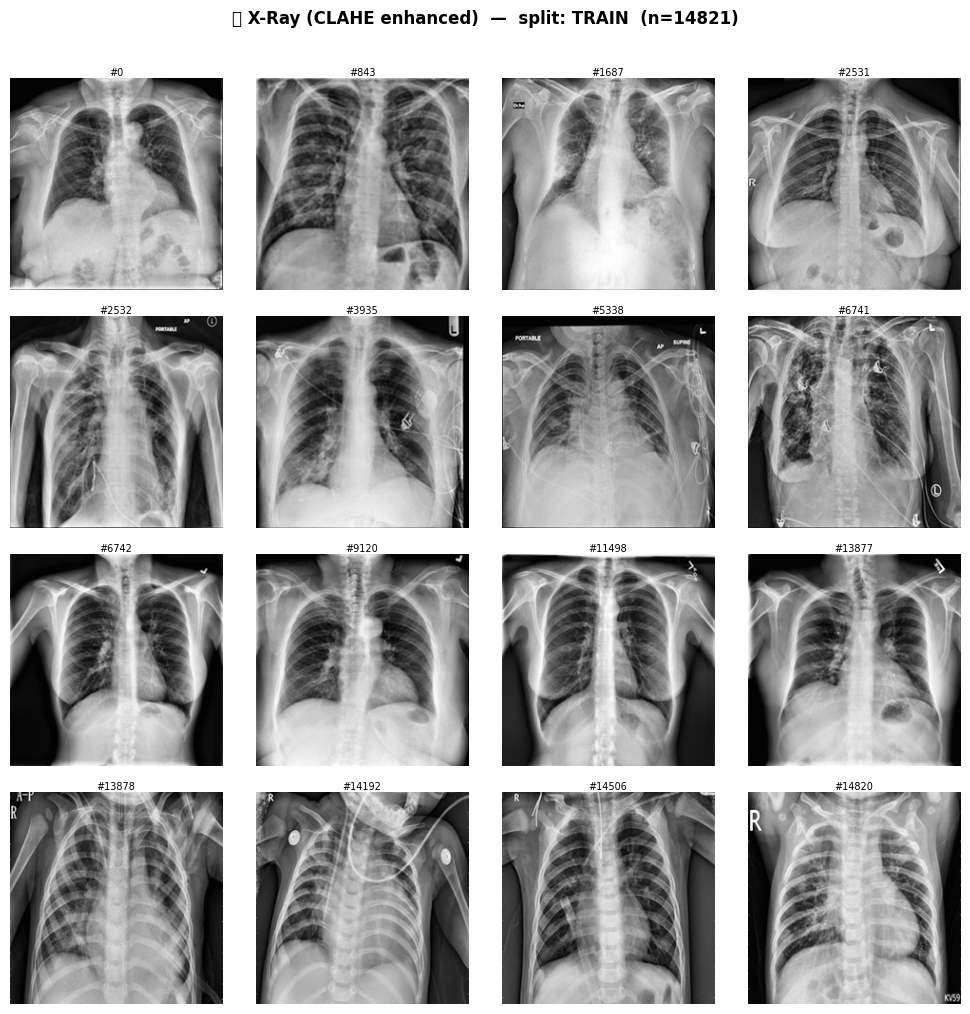

✅  Saved → preprocessed/xray_train_samples.png


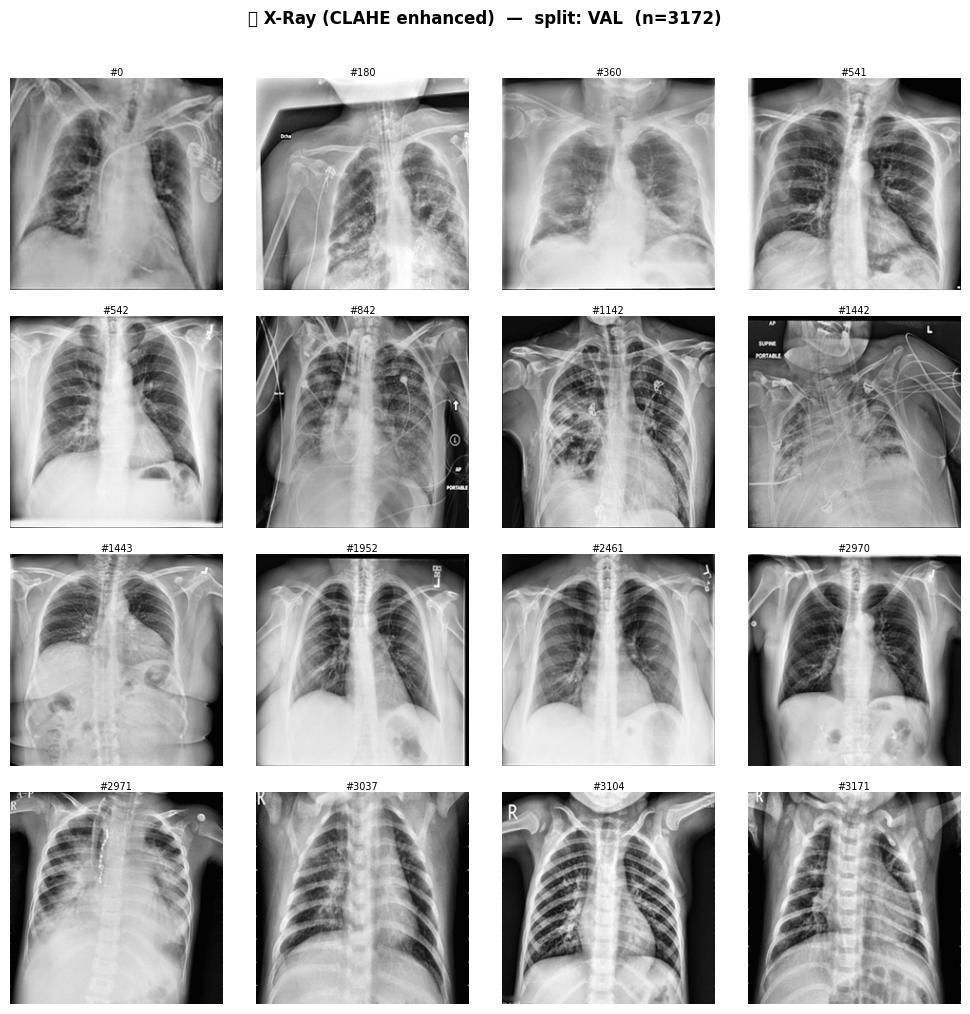

✅  Saved → preprocessed/xray_val_samples.png


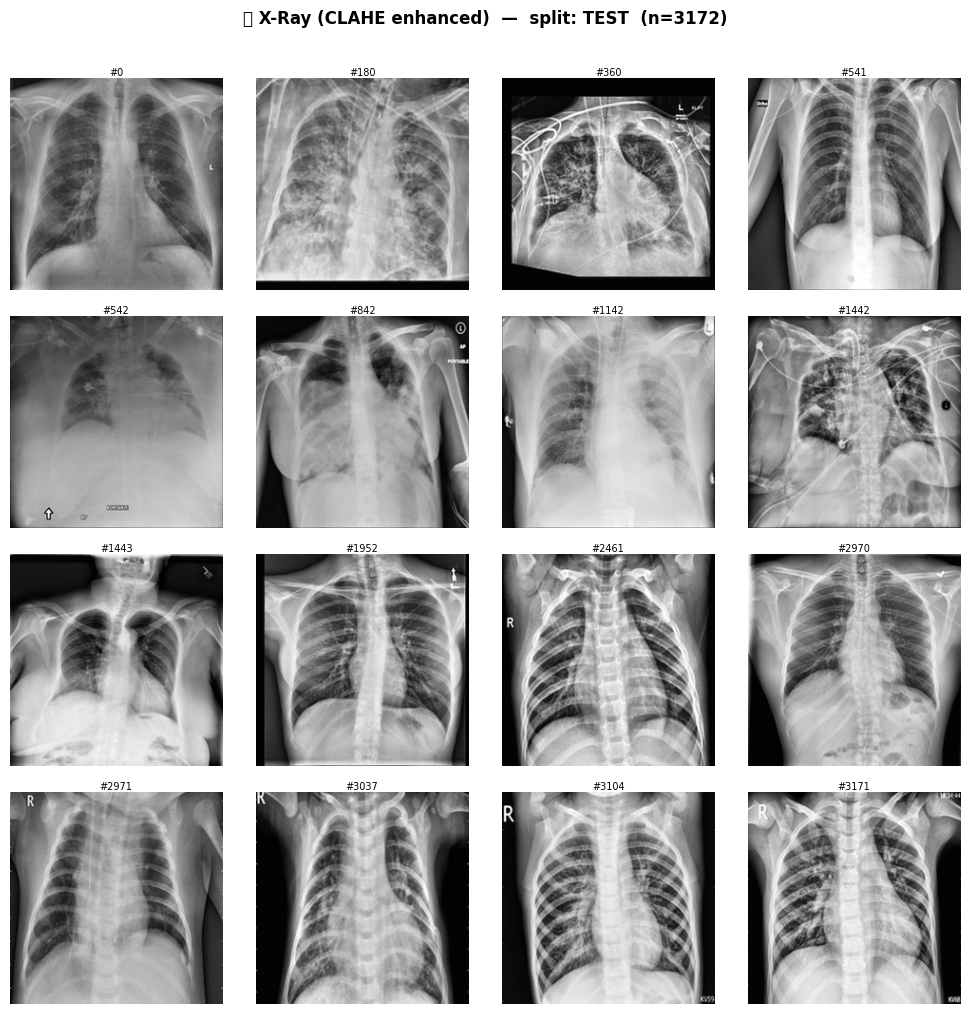

✅  Saved → preprocessed/xray_test_samples.png


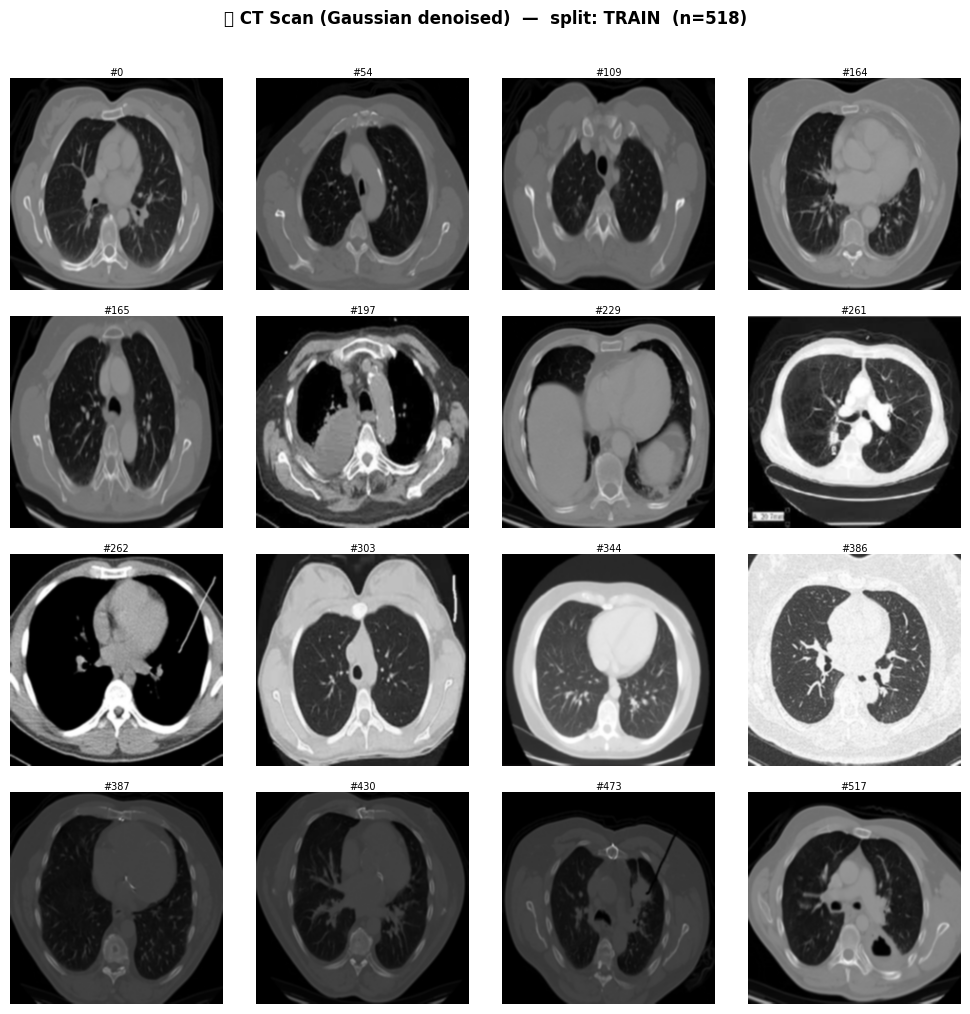

✅  Saved → preprocessed/ct_train_samples.png


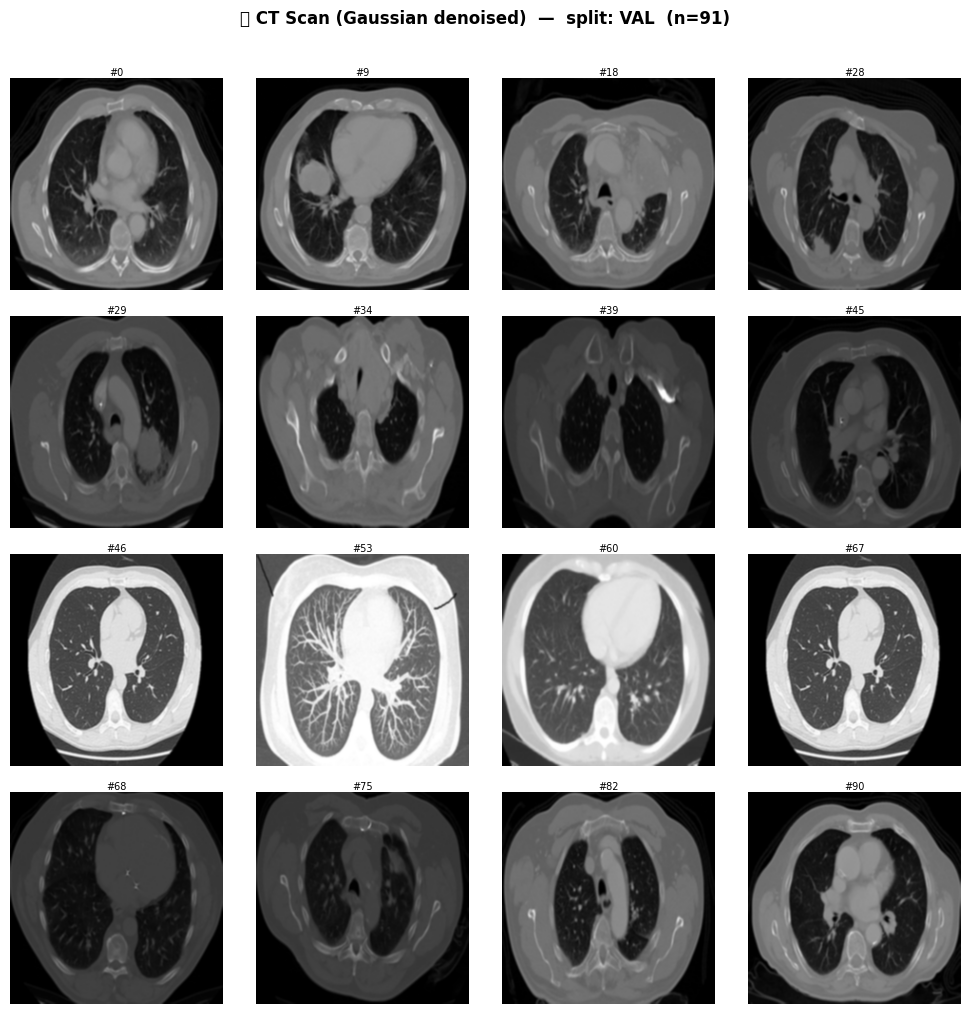

✅  Saved → preprocessed/ct_val_samples.png


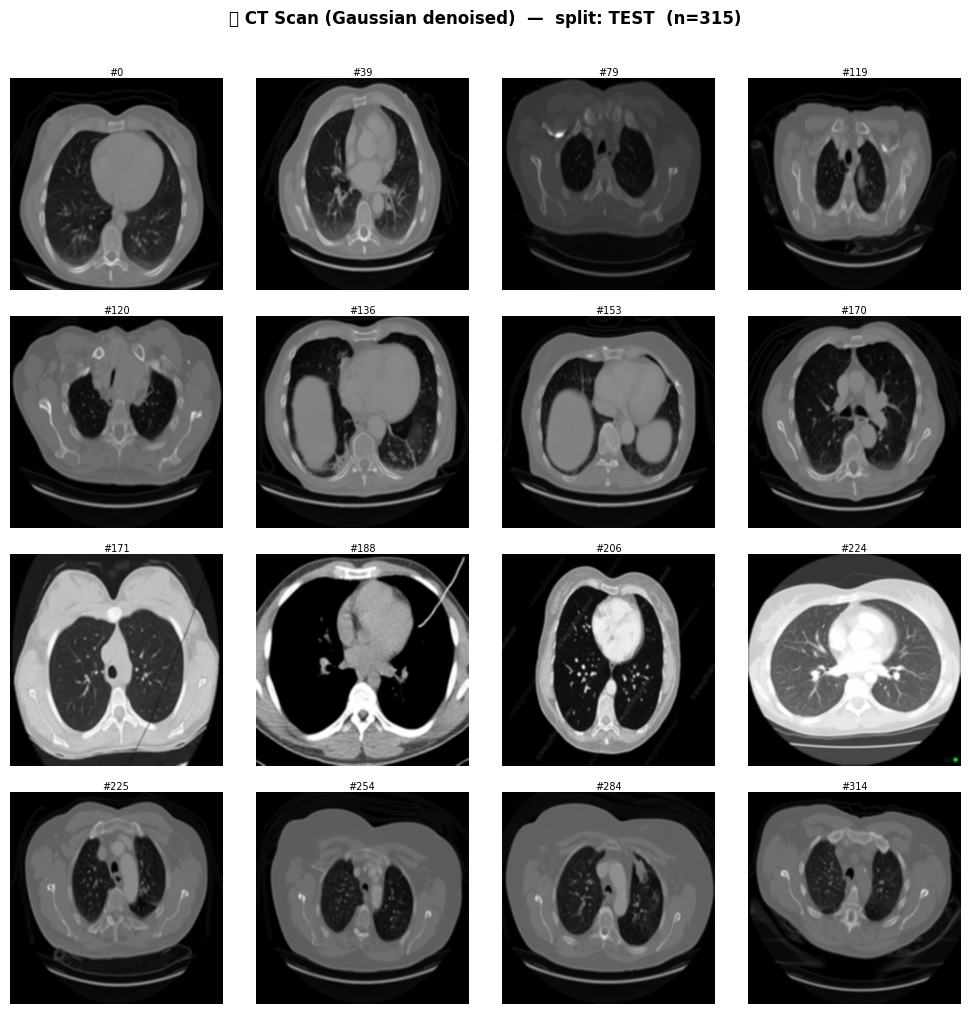

✅  Saved → preprocessed/ct_test_samples.png


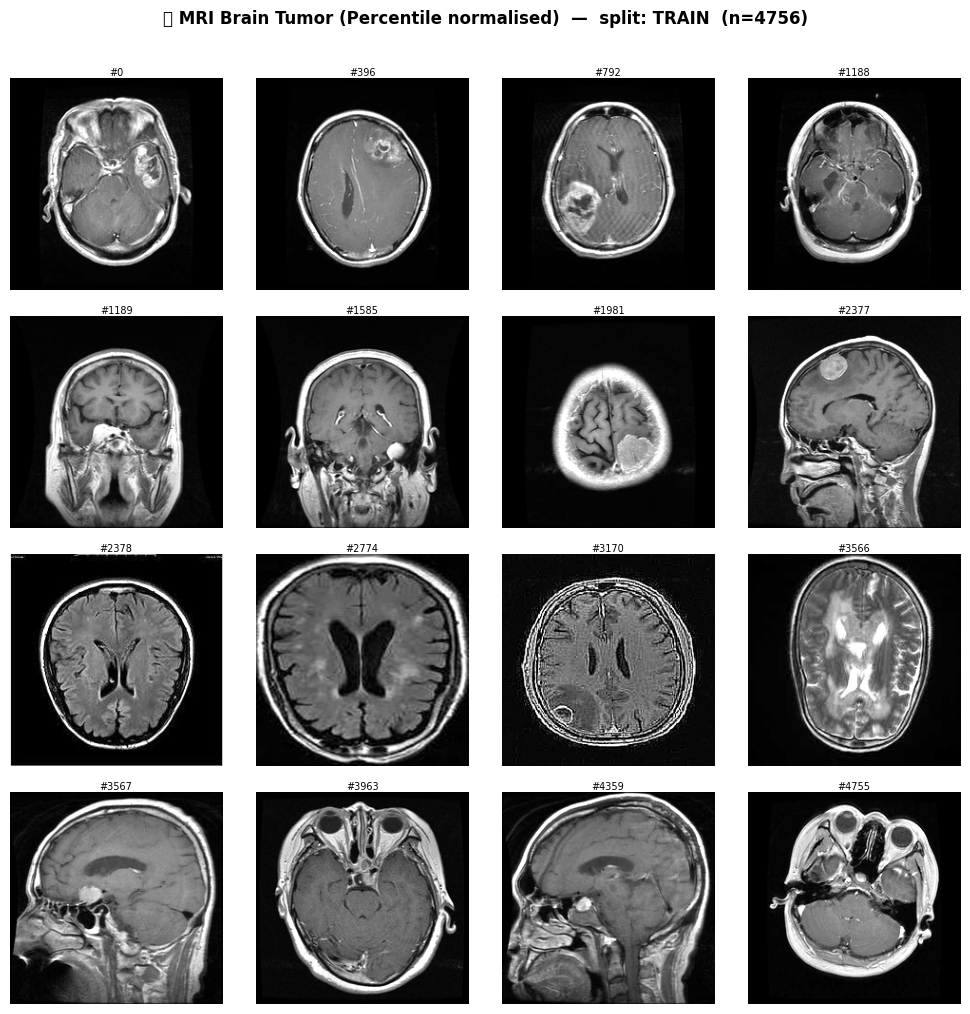

✅  Saved → preprocessed/mri_train_samples.png


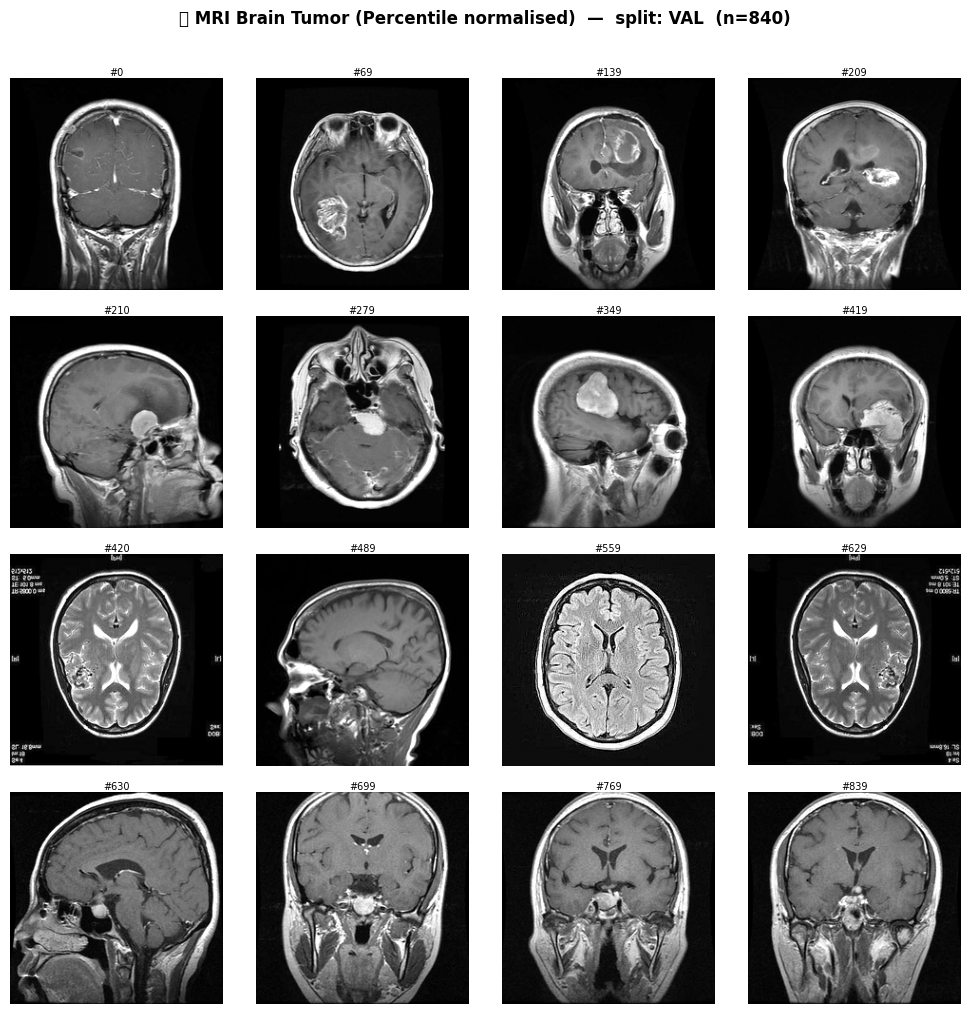

✅  Saved → preprocessed/mri_val_samples.png


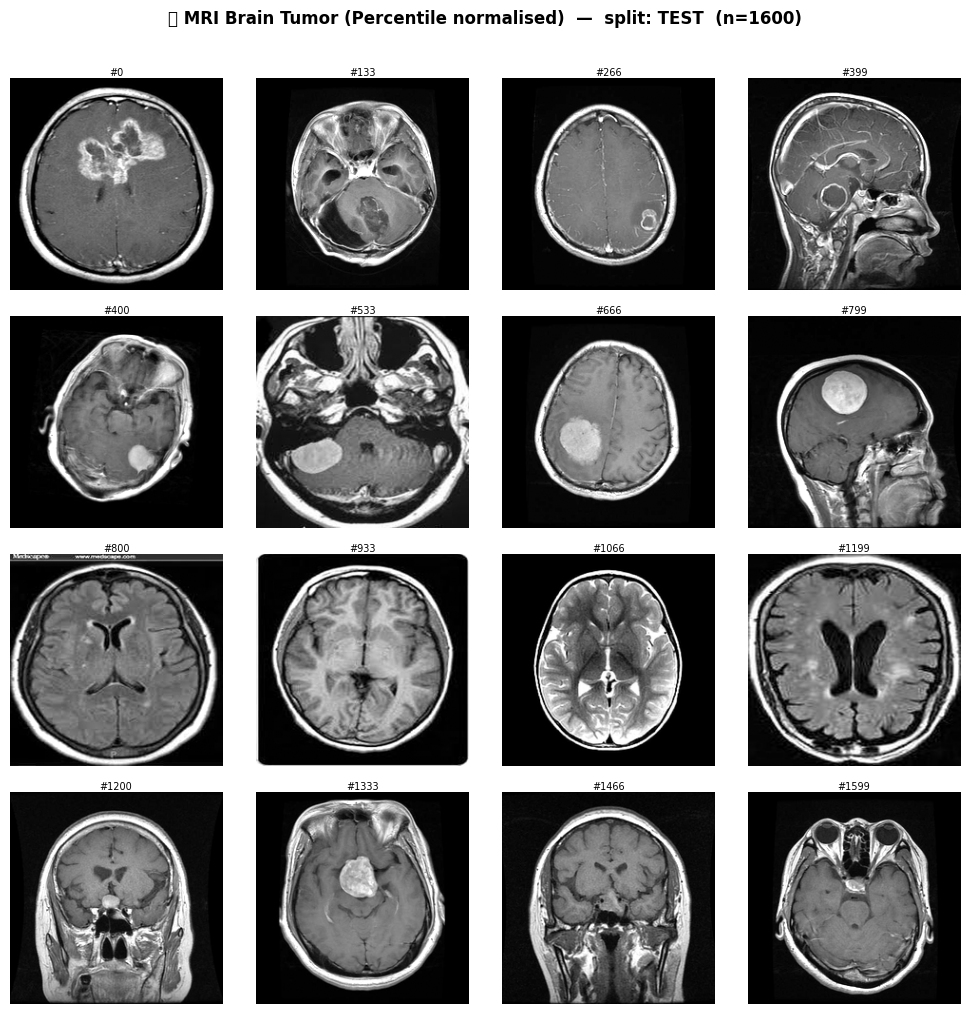

✅  Saved → preprocessed/mri_test_samples.png

✅  All preprocessed sample grids displayed.


In [7]:
# ── Visualise Preprocessed Samples ───────────────────────────────────────────
# Add this cell at the END of preprocessing.ipynb (after Cell 6 verification).
# Shows 4 sample images per modality per split — reads via memmap (RAM-safe).

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

OUT_DIR  = Path('preprocessed')
IMG_SIZE = 224

MODALITY_CLASSES = {
    'xray': ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia'],
    'ct':   ['adenocarcinoma', 'large cell carcinoma', 'normal', 'squamous cell carcinoma'],
    'mri':  ['glioma', 'meningioma', 'notumor', 'pituitary'],
}

MODALITY_TITLES = {
    'xray': '🫁 X-Ray (CLAHE enhanced)',
    'ct':   '🔬 CT Scan (Gaussian denoised)',
    'mri':  '🧲 MRI Brain Tumor (Percentile normalised)',
}

N_SHOW = 4   # samples per class to show

for modality in ['xray', 'ct', 'mri']:
    classes = MODALITY_CLASSES[modality]
    n_cls   = len(classes)

    for split in ['train', 'val', 'test']:
        x_path = OUT_DIR / modality / split / 'X.npy'
        y_path = OUT_DIR / modality / split / 'y.npy'

        if not (x_path.exists() and y_path.exists()):
            print(f'  ⚠️  {modality}/{split} not found — skipping')
            continue

        y  = np.load(str(y_path))
        n  = len(y)
        X  = np.memmap(str(x_path), dtype='float32', mode='r',
                       shape=(n, IMG_SIZE, IMG_SIZE, 3))

        fig, axes = plt.subplots(
            n_cls, N_SHOW,
            figsize=(N_SHOW * 2.5, n_cls * 2.5)
        )
        # Ensure axes is always 2D even for 1 class
        if n_cls == 1:
            axes = axes[np.newaxis, :]

        fig.suptitle(
            f'{MODALITY_TITLES[modality]}  —  split: {split.upper()}  '
            f'(n={n})',
            fontsize=12, fontweight='bold', y=1.01
        )

        for row, cls_idx in enumerate(range(n_cls)):
            # Find indices for this class
            cls_indices = np.where(y == cls_idx)[0]

            if len(cls_indices) == 0:
                for col in range(N_SHOW):
                    axes[row, col].axis('off')
                    axes[row, col].set_title('no samples', fontsize=7)
                continue

            # Pick N_SHOW evenly spaced samples (deterministic, no random)
            pick = np.linspace(0, len(cls_indices) - 1, N_SHOW, dtype=int)
            picked_indices = cls_indices[pick]

            for col, idx in enumerate(picked_indices):
                img = np.array(X[idx], copy=True)   # (224,224,3) float32 [0,1]

                # Clip to [0,1] for display safety
                img = np.clip(img, 0.0, 1.0)

                # Grayscale modalities (xray/mri) → show in gray
                if modality in ('xray', 'mri'):
                    axes[row, col].imshow(img[:, :, 0], cmap='gray', vmin=0, vmax=1)
                else:
                    axes[row, col].imshow(img)

                axes[row, col].axis('off')

                # Label only the first column with the class name
                if col == 0:
                    axes[row, col].set_ylabel(
                        classes[cls_idx], fontsize=8,
                        rotation=0, labelpad=60, va='center'
                    )

                # Show sample index under image
                axes[row, col].set_title(f'#{idx}', fontsize=7, pad=2)

        plt.tight_layout()

        save_path = f'preprocessed/{modality}_{split}_samples.png'
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        plt.show()
        print(f'✅  Saved → {save_path}')

        del X  # close memmap
print('\n✅  All preprocessed sample grids displayed.')

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from collections import Counter

OUT_DIR  = Path('preprocessed')
IMG_SIZE = 224

MODALITY_CLASSES = {
    'xray': ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia'],
    'ct':   ['adenocarcinoma', 'large cell carcinoma',
             'normal', 'squamous cell carcinoma'],
    'mri':  ['glioma', 'meningioma', 'notumor', 'pituitary'],
}

MODALITY_COLORS = {
    'xray': '#1E88E5',
    'ct':   '#43A047',
    'mri':  '#8E24AA',
}

SPLIT_COLORS = {'train': '#2196F3', 'val': '#FF9800', 'test': '#F44336'}

# ── Helper: load labels only (tiny, safe) ────────────────────────────────────
def load_y(modality, split):
    p = OUT_DIR / modality / split / 'y.npy'
    return np.load(str(p)) if p.exists() else np.array([])

# ── Helper: load N random samples from memmap (RAM-safe) ─────────────────────
def load_samples(modality, split, n=200, class_filter=None, seed=0):
    """Returns (images, labels) — reads at most n samples via memmap."""
    y_path = OUT_DIR / modality / split / 'y.npy'
    x_path = OUT_DIR / modality / split / 'X.npy'
    if not (y_path.exists() and x_path.exists()):
        return np.array([]), np.array([])
    y   = np.load(str(y_path))
    idx = np.where(y == class_filter)[0] if class_filter is not None \
          else np.arange(len(y))
    rng = np.random.default_rng(seed)
    idx = rng.choice(idx, size=min(n, len(idx)), replace=False)
    idx = np.sort(idx)
    X_mm = np.memmap(str(x_path), dtype='float32', mode='r',
                     shape=(len(y), IMG_SIZE, IMG_SIZE, 3))
    imgs = np.array(X_mm[idx], copy=True)
    del X_mm
    return imgs, y[idx]


📊 PLOT 3 — Pixel Intensity Histograms


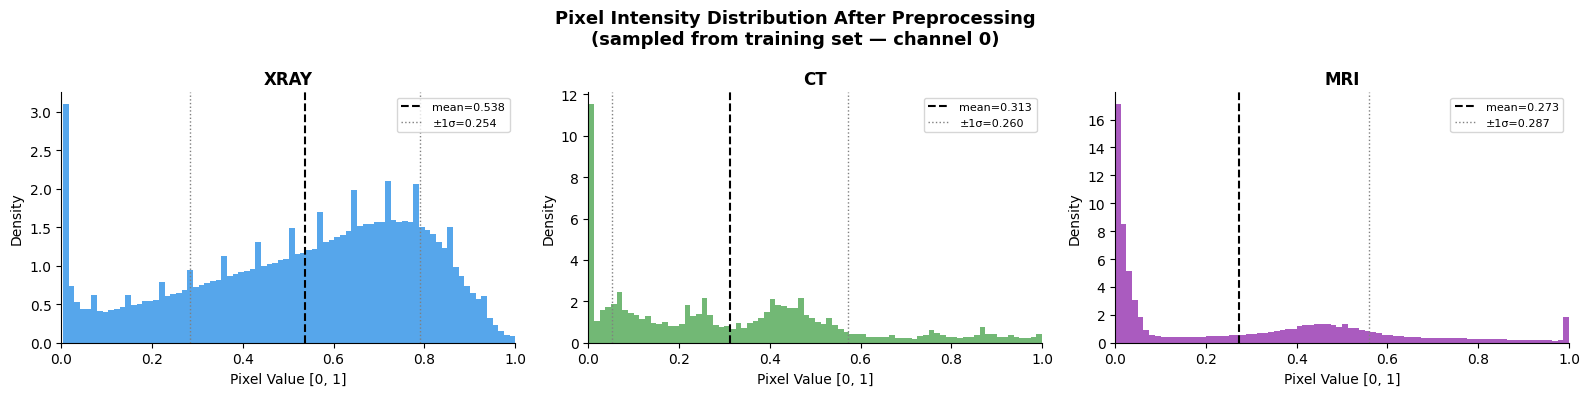

  ✅ Saved → preprocessed/plot3_intensity_histograms.png


In [11]:
# ══════════════════════════════════════════════════════════════════════════════
# PLOT 3 — Pixel Intensity Histograms
# Shows the distribution of pixel values after preprocessing.
# X-Ray/MRI should peak near 0–0.5 (dark background), CT more spread.
# If all values are 0 or 1, preprocessing went wrong.
# ══════════════════════════════════════════════════════════════════════════════
print('\n📊 PLOT 3 — Pixel Intensity Histograms')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Pixel Intensity Distribution After Preprocessing\n'
             '(sampled from training set — channel 0)',
             fontsize=13, fontweight='bold')

for ax, modality in zip(axes, ['xray', 'ct', 'mri']):
    classes = MODALITY_CLASSES[modality]
    color   = MODALITY_COLORS[modality]

    # Sample 50 images per class
    all_pixels = []
    for cls_idx in range(len(classes)):
        imgs, _ = load_samples(modality, 'train', n=50,
                               class_filter=cls_idx, seed=cls_idx)
        if len(imgs) > 0:
            # Flatten channel 0 pixels
            all_pixels.append(imgs[:, :, :, 0].ravel())

    if len(all_pixels) == 0:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                ha='center', va='center')
        continue

    pixels = np.concatenate(all_pixels)

    ax.hist(pixels, bins=80, color=color, alpha=0.75,
            edgecolor='none', density=True)
    ax.axvline(pixels.mean(), color='black', lw=1.5,
               linestyle='--', label=f'mean={pixels.mean():.3f}')
    ax.axvline(pixels.mean() + pixels.std(), color='gray', lw=1,
               linestyle=':', label=f'±1σ={pixels.std():.3f}')
    ax.axvline(pixels.mean() - pixels.std(), color='gray', lw=1,
               linestyle=':')

    ax.set_xlim(0, 1)
    ax.set_xlabel('Pixel Value [0, 1]')
    ax.set_ylabel('Density')
    ax.set_title(f'{modality.upper()}', fontweight='bold')
    ax.legend(fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('preprocessed/plot3_intensity_histograms.png', dpi=130,
            bbox_inches='tight')
plt.show()
print('  ✅ Saved → preprocessed/plot3_intensity_histograms.png')


📊 PLOT 4 — Before vs After Preprocessing


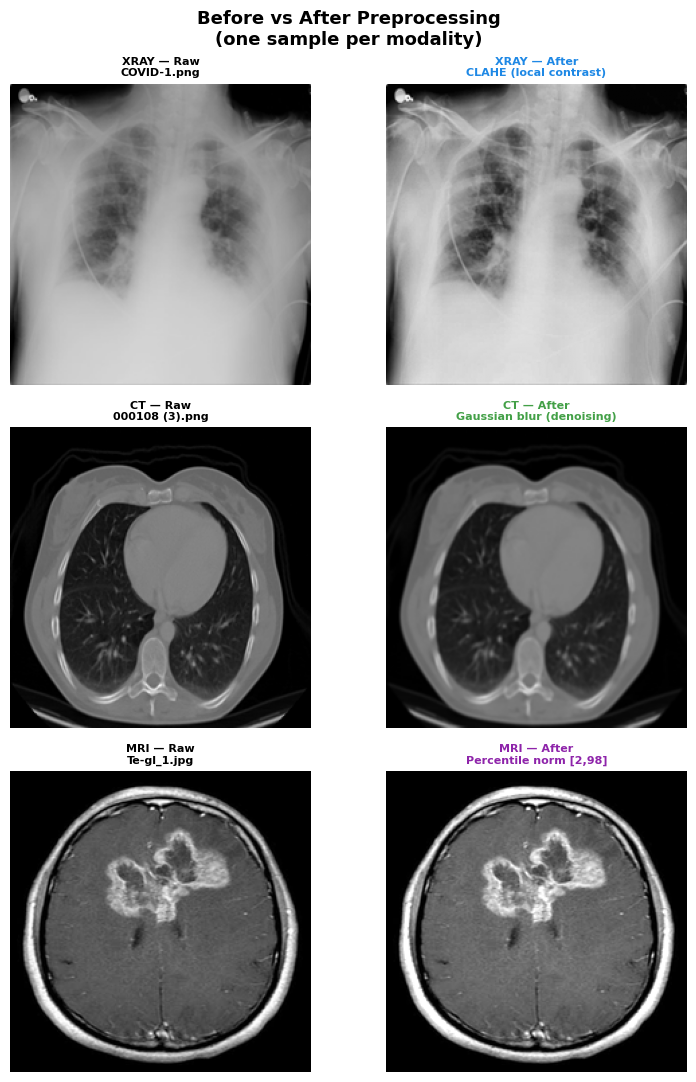

  ✅ Saved → preprocessed/plot4_before_after.png


In [12]:
# ══════════════════════════════════════════════════════════════════════════════
# PLOT 4 — Before vs After Preprocessing (Side-by-Side)
# Shows raw image vs preprocessed image for one sample from each modality.
# Visually confirms CLAHE sharpening, Gaussian smoothing, percentile norm.
# Raw images are read directly from DATASETS/ folder.
# ══════════════════════════════════════════════════════════════════════════════
print('\n📊 PLOT 4 — Before vs After Preprocessing')

import cv2
from PIL import Image as PILImage

DATA_DIR = Path('DATASETS')   # adjust if your folder name differs

def load_raw_image(modality):
    """Find one sample raw image path for the given modality."""
    search_roots = {
        'xray': [DATA_DIR / d for d in ['XRAY', 'xray', 'Xray']],
        'ct':   [DATA_DIR / d for d in ['CT', 'ct']],
        'mri':  [DATA_DIR / d for d in ['MRI', 'mri']],
    }
    valid_exts = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
    for root in search_roots[modality]:
        if not root.exists():
            continue
        for path in root.rglob('*'):
            if path.suffix.lower() in valid_exts:
                try:
                    img = PILImage.open(path).convert('RGB')
                    img = img.resize((IMG_SIZE, IMG_SIZE), PILImage.LANCZOS)
                    return np.array(img, dtype=np.uint8), path
                except Exception:
                    continue
    return None, None


def preprocess_xray(img): 
    gray  = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    gray  = clahe.apply(gray)
    f     = gray.astype(np.float32) / 255.0
    return np.stack([f, f, f], axis=-1)

def preprocess_ct(img):
    blurred = cv2.GaussianBlur(img, (3, 3), 0)
    return blurred.astype(np.float32) / 255.0

def preprocess_mri(img):
    gray    = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    p2, p98 = np.percentile(gray, [2, 98])
    gray    = np.clip(gray, p2, p98)
    gray    = (gray - p2) / (p98 - p2 + 1e-8)
    return np.stack([gray, gray, gray], axis=-1).astype(np.float32)

PREPROCESSORS = {'xray': preprocess_xray,
                 'ct':   preprocess_ct,
                 'mri':  preprocess_mri}

PREPROCESSING_LABELS = {
    'xray': 'CLAHE (local contrast)',
    'ct':   'Gaussian blur (denoising)',
    'mri':  'Percentile norm [2,98]',
}

fig, axes = plt.subplots(3, 2, figsize=(8, 11))
fig.suptitle('Before vs After Preprocessing\n(one sample per modality)',
             fontsize=13, fontweight='bold')

for row, modality in enumerate(['xray', 'ct', 'mri']):
    raw_img, raw_path = load_raw_image(modality)

    if raw_img is None:
        for col in range(2):
            axes[row, col].text(0.5, 0.5, f'{modality.upper()}\nnot found',
                                transform=axes[row, col].transAxes,
                                ha='center', va='center', fontsize=10)
            axes[row, col].axis('off')
        continue

    proc_img = PREPROCESSORS[modality](raw_img)

    # ── Before ──
    axes[row, 0].imshow(raw_img)
    axes[row, 0].set_title(f'{modality.upper()} — Raw\n{raw_path.name}',
                            fontsize=8, fontweight='bold')
    axes[row, 0].axis('off')

    # ── After ──
    if modality in ('xray', 'mri'):
        axes[row, 1].imshow(proc_img[:, :, 0], cmap='gray', vmin=0, vmax=1)
    else:
        axes[row, 1].imshow(np.clip(proc_img, 0, 1))
    axes[row, 1].set_title(
        f'{modality.upper()} — After\n{PREPROCESSING_LABELS[modality]}',
        fontsize=8, fontweight='bold',
        color=MODALITY_COLORS[modality])
    axes[row, 1].axis('off')

plt.tight_layout()
plt.savefig('preprocessed/plot4_before_after.png', dpi=130,
            bbox_inches='tight')
plt.show()
print('  ✅ Saved → preprocessed/plot4_before_after.png')


📊 PLOT 5 — Per-Class Mean Image (Training Set)


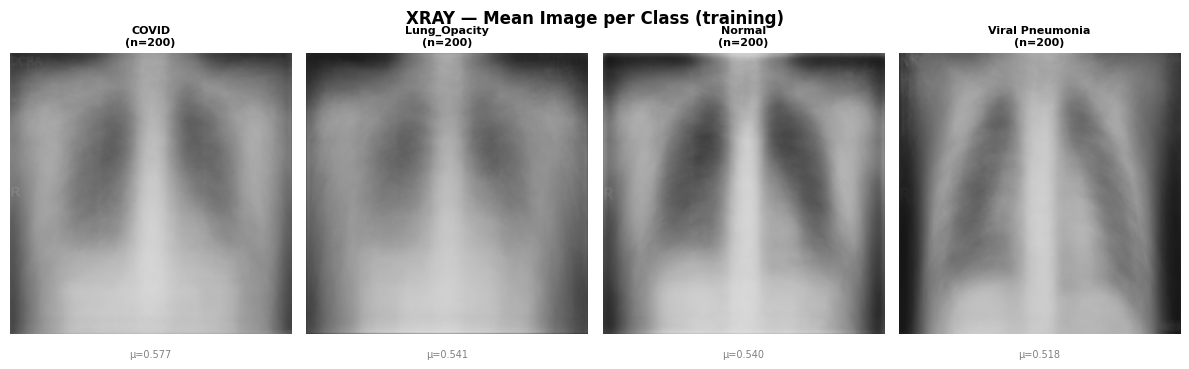

  ✅ Saved → preprocessed/plot5_xray_mean_images.png


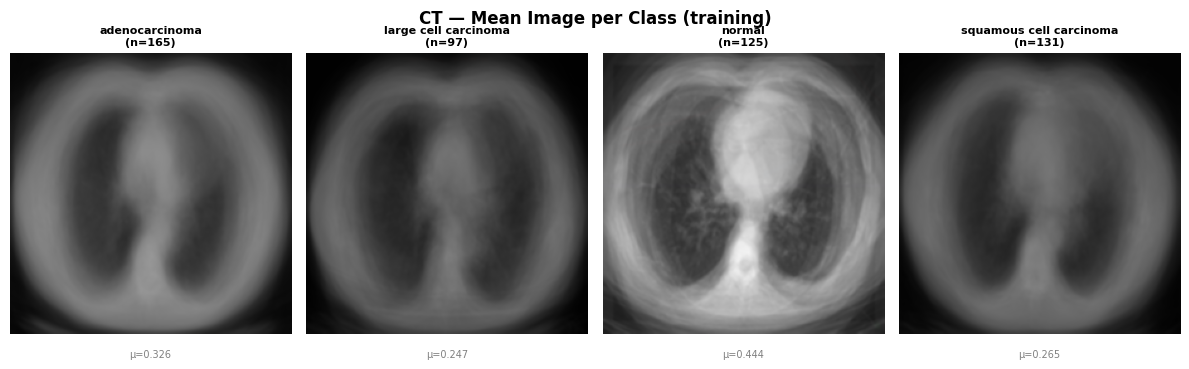

  ✅ Saved → preprocessed/plot5_ct_mean_images.png


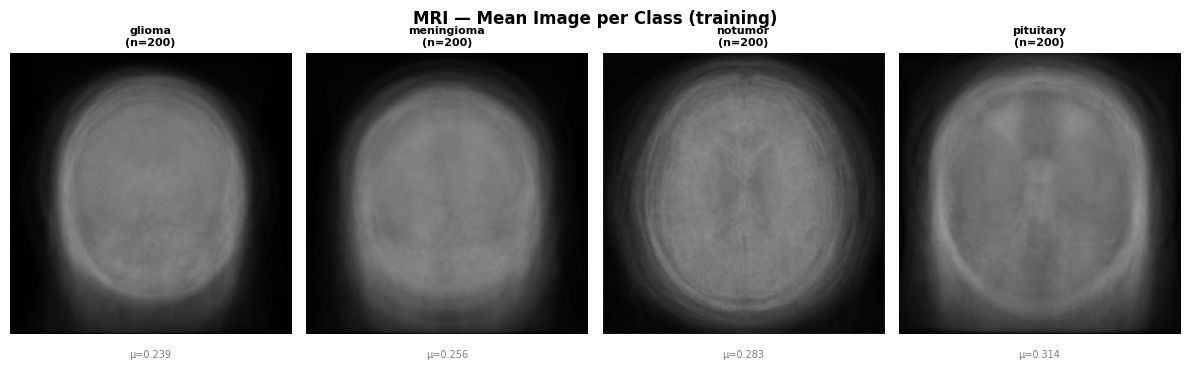

  ✅ Saved → preprocessed/plot5_mri_mean_images.png


In [13]:
# ══════════════════════════════════════════════════════════════════════════════
# PLOT 5 — Per-Class Mean Image
# Average of all training images in each class.
# Useful to confirm that different classes look visually distinct.
# If two classes have similar mean images, the model will struggle.
# ══════════════════════════════════════════════════════════════════════════════
print('\n📊 PLOT 5 — Per-Class Mean Image (Training Set)')

for modality in ['xray', 'ct', 'mri']:
    classes = MODALITY_CLASSES[modality]
    n_cls   = len(classes)

    fig, axes = plt.subplots(1, n_cls, figsize=(n_cls * 3, 3.5))
    if n_cls == 1:
        axes = [axes]
    fig.suptitle(f'{modality.upper()} — Mean Image per Class (training)',
                 fontsize=12, fontweight='bold')

    for cls_idx, cls_name in enumerate(classes):
        # Sample up to 200 images for mean calculation
        imgs, _ = load_samples(modality, 'train', n=200,
                               class_filter=cls_idx, seed=42)

        ax = axes[cls_idx]
        if len(imgs) == 0:
            ax.text(0.5, 0.5, 'no data', transform=ax.transAxes,
                    ha='center', va='center')
            ax.axis('off')
            continue

        mean_img = imgs.mean(axis=0)   # (224, 224, 3)

        if modality in ('xray', 'mri'):
            ax.imshow(mean_img[:, :, 0], cmap='gray', vmin=0, vmax=1)
        else:
            ax.imshow(np.clip(mean_img, 0, 1))

        ax.set_title(f'{cls_name}\n(n={len(imgs)})', fontsize=8,
                     fontweight='bold')
        ax.axis('off')

        # Annotate brightness
        brightness = mean_img.mean()
        ax.text(0.5, -0.08, f'μ={brightness:.3f}',
                transform=ax.transAxes, ha='center',
                fontsize=7, color='gray')

    plt.tight_layout()
    save_path = f'preprocessed/plot5_{modality}_mean_images.png'
    plt.savefig(save_path, dpi=130, bbox_inches='tight')
    plt.show()
    print(f'  ✅ Saved → {save_path}')


📊 PLOT 6 — Dataset Summary Table

  Modality Split    Class                               Count
  ------------------------------------------------------------
  XRAY     Train    COVID                                2532
  XRAY     Train    Lung_Opacity                         4210
  XRAY     Train    Normal                               7136
  XRAY     Train    Viral Pneumonia                       943
  XRAY     Val      COVID                                 542
  XRAY     Val      Lung_Opacity                          901
  XRAY     Val      Normal                               1528
  XRAY     Val      Viral Pneumonia                       201
  XRAY     Test     COVID                                 542
  XRAY     Test     Lung_Opacity                          901
  XRAY     Test     Normal                               1528
  XRAY     Test     Viral Pneumonia                       201

  CT       Train    adenocarcinoma                        165
  CT       Train    large cell ca

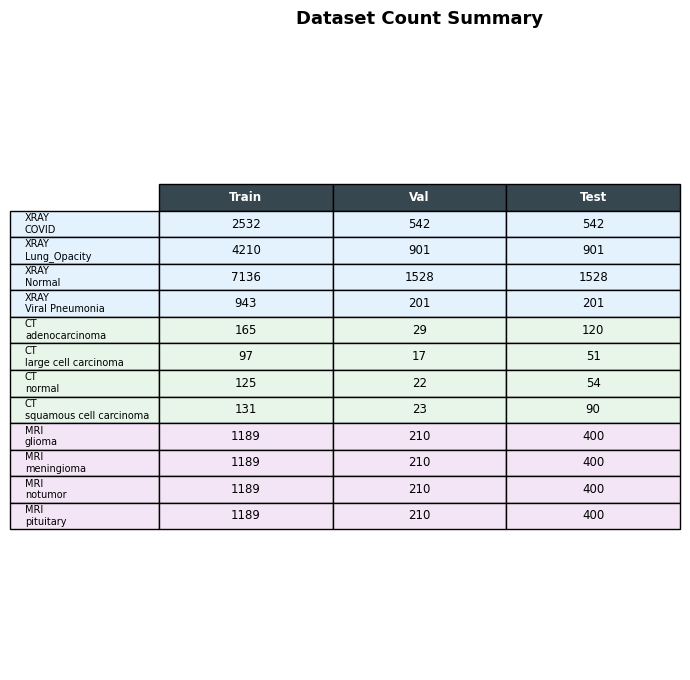

  ✅ Saved → preprocessed/plot6_dataset_summary_table.png

════════════════════════════════════════════════════════════
ALL DIAGNOSTIC PLOTS COMPLETE
════════════════════════════════════════════════════════════
Files saved in preprocessed/:
  1. plot1_class_distribution.png
  2. plot2_split_proportions.png
  3. plot3_intensity_histograms.png
  4. plot4_before_after.png
  5. plot5_xray_mean_images.png
  6. plot5_ct_mean_images.png
  7. plot5_mri_mean_images.png
  8. plot6_dataset_summary_table.png


In [14]:
# ══════════════════════════════════════════════════════════════════════════════
# PLOT 6 — Dataset Summary Table
# Compact printed + visual table showing all counts at a glance.
# ══════════════════════════════════════════════════════════════════════════════
print('\n📊 PLOT 6 — Dataset Summary Table')

rows = []
for modality in ['xray', 'ct', 'mri']:
    classes = MODALITY_CLASSES[modality]
    for split in ['train', 'val', 'test']:
        y = load_y(modality, split)
        if len(y) == 0:
            continue
        for cls_idx, cls_name in enumerate(classes):
            count = int((y == cls_idx).sum())
            rows.append({
                'Modality': modality.upper(),
                'Split':    split.capitalize(),
                'Class':    cls_name,
                'Count':    count,
            })

# ── Print table ──────────────────────────────────────────────────────────────
print(f'\n  {"Modality":<8} {"Split":<8} {"Class":<34} {"Count":>6}')
print('  ' + '-' * 60)
prev_mod = ''
for r in rows:
    sep = '\n' if r['Modality'] != prev_mod and prev_mod != '' else ''
    print(f'{sep}  {r["Modality"]:<8} {r["Split"]:<8} '
          f'{r["Class"]:<34} {r["Count"]:>6}')
    prev_mod = r['Modality']

# ── Visual heatmap table ──────────────────────────────────────────────────────
import pandas as pd

# Build pivot: rows=modality+class, cols=split
data = {}
for modality in ['xray', 'ct', 'mri']:
    classes = MODALITY_CLASSES[modality]
    for cls in classes:
        key = f'{modality.upper()}\n{cls}'
        data[key] = {}
        for split in ['train', 'val', 'test']:
            y = load_y(modality, split)
            cls_idx = classes.index(cls)
            data[key][split.capitalize()] = int((y == cls_idx).sum()) \
                if len(y) > 0 else 0

df = pd.DataFrame(data).T
df.index.name = 'Modality / Class'

fig, ax = plt.subplots(figsize=(7, len(df) * 0.45 + 1.5))
ax.axis('off')

col_labels = ['Train', 'Val', 'Test']
table_data  = [[str(df.loc[idx, col]) for col in col_labels]
               for idx in df.index]
row_labels  = list(df.index)

tbl = ax.table(
    cellText    = table_data,
    rowLabels   = row_labels,
    colLabels   = col_labels,
    loc         = 'center',
    cellLoc     = 'center',
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
tbl.scale(1, 1.35)

# Colour-code rows by modality
mod_colors = {'XRAY': '#E3F2FD', 'CT': '#E8F5E9', 'MRI': '#F3E5F5'}
for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_facecolor('#37474F')
        cell.set_text_props(color='white', fontweight='bold')
    elif col == -1:
        mod = row_labels[row - 1].split('\n')[0]
        cell.set_facecolor(mod_colors.get(mod, '#FAFAFA'))
        cell.set_text_props(fontsize=7)
    else:
        mod = row_labels[row - 1].split('\n')[0]
        cell.set_facecolor(mod_colors.get(mod, '#FFFFFF'))

ax.set_title('Dataset Count Summary', fontsize=13,
             fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig('preprocessed/plot6_dataset_summary_table.png', dpi=130,
            bbox_inches='tight')
plt.show()
print('  ✅ Saved → preprocessed/plot6_dataset_summary_table.png')

print('\n' + '═'*60)
print('ALL DIAGNOSTIC PLOTS COMPLETE')
print('═'*60)
print('Files saved in preprocessed/:')
for i, name in enumerate([
    'plot1_class_distribution.png',
    'plot2_split_proportions.png',
    'plot3_intensity_histograms.png',
    'plot4_before_after.png',
    'plot5_xray_mean_images.png',
    'plot5_ct_mean_images.png',
    'plot5_mri_mean_images.png',
    'plot6_dataset_summary_table.png',
], 1):
    print(f'  {i}. {name}')
